In [1]:
import statsmodels.api as sm
import pandas as pd

In [2]:
df = pd.read_csv("data/final.csv")

In [3]:
df

,Unnamed: 0,log_ret,monthly_return,IV,RV,VRP,log_PE,log_PD,CAY,BAA,AAA,GS10,TB3MS,DFSP,TMSP,RREL,excess_ret,cay_imputed,VIX3M
0,2008-03-31,-0.014079,-0.025783,0.065171,0.058995,0.006176,3.079178,3.875335,0.006081,6.82,5.53,3.74,2.12,1.29,1.62,-1.805000,-0.027531,0.006081,25.394500
1,2008-04-30,0.048108,-0.013980,0.073852,0.075129,-0.001277,3.082243,3.840204,0.009843,6.89,5.51,3.51,1.26,1.38,2.25,-2.358333,-0.015024,0.009843,26.888000
2,2008-05-31,0.013493,0.049283,0.046684,0.046326,0.000358,3.173155,3.875230,0.009843,6.97,5.55,3.68,1.29,1.42,2.39,-2.030000,0.048215,0.009843,22.488636
3,2008-06-30,-0.091226,0.013585,0.033596,0.037002,-0.003406,3.250590,3.894051,0.009843,6.93,5.57,3.88,1.73,1.36,2.15,-1.340000,0.012155,0.009843,20.617619
4,2008-07-31,-0.009495,-0.087189,0.049107,0.050400,-0.001293,3.262303,3.844112,-0.006757,7.07,5.68,4.10,1.86,1.39,2.24,-0.980833,-0.088725,-0.006757,23.129524
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,2021-01-31,-0.013283,0.027612,0.050212,0.031184,0.019028,3.670143,4.149581,-0.043572,3.16,2.26,0.93,0.09,0.90,0.84,-0.275000,0.027537,-0.043572,25.429091
155,2021-02-28,0.028761,-0.013195,0.063758,0.040120,0.023637,3.582525,4.179569,-0.043469,3.24,2.45,1.08,0.08,0.79,1.00,-0.165000,-0.013261,-0.043469,27.552632
156,2021-03-31,0.041269,0.029179,0.054342,0.037756,0.016587,3.503641,4.206646,-0.043030,3.42,2.70,1.26,0.04,0.72,1.22,-0.081667,0.029145,-0.043030,27.811579
157,2021-04-30,0.051760,0.042132,0.048388,0.050433,-0.002045,3.417831,4.217321,-0.042450,3.74,3.04,1.61,0.03,0.70,1.58,-0.070000,0.042107,-0.042450,25.341739


In [4]:
df_reg = df.copy()
df_reg["excess_ret_lead"] = df_reg["excess_ret"].shift(-1)

In [5]:
# Regressionsdaten
reg_data = df_reg[["excess_ret_lead", "VRP"]].dropna()

X = sm.add_constant(reg_data["VRP"])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                    0.3413
Date:                Tue, 07 Apr 2026   Prob (F-statistic):              0.560
Time:                        23:43:28   Log-Likelihood:                 263.27
No. Observations:                 158   AIC:                            -522.5
Df Residuals:                     156   BIC:                            -516.4
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0073      0.004      2.012      0.0

In [6]:
controls = ["log_PE", "DFSP", "TMSP", "CAY"]

reg_data = df_reg[["excess_ret_lead", "VRP"] + controls].dropna()

X = sm.add_constant(reg_data[["VRP"] + controls])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     1.946
Date:                Tue, 07 Apr 2026   Prob (F-statistic):             0.0898
Time:                        23:43:28   Log-Likelihood:                 266.73
No. Observations:                 158   AIC:                            -521.5
Df Residuals:                     152   BIC:                            -503.1
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0034      0.047      0.072      0.9

In [7]:
k = 12

df_reg[f"ret_{k}m"] = df_reg["excess_ret"].rolling(k).sum().shift(-k)

reg_data = df_reg[[f"ret_{k}m", "VRP"]].dropna()

X = sm.add_constant(reg_data["VRP"])
y = reg_data[f"ret_{k}m"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": k})

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                ret_12m   R-squared:                       0.094
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     16.38
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           8.42e-05
Time:                        23:43:28   Log-Likelihood:                 86.526
No. Observations:                 147   AIC:                            -169.1
Df Residuals:                     145   BIC:                            -163.1
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0952      0.026      3.681      0.0

## Polynomial Regression

In [8]:
df_reg["VRP_sq"] = df_reg["VRP"]**2

reg_data = df_reg[["excess_ret_lead", "VRP", "VRP_sq"]].dropna()

X = sm.add_constant(reg_data[["VRP", "VRP_sq"]])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     9.464
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           0.000132
Time:                        23:43:28   Log-Likelihood:                 268.72
No. Observations:                 158   AIC:                            -531.4
Df Residuals:                     155   BIC:                            -522.2
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0096      0.004      2.721      0.0

## Spline

In [9]:
from patsy import dmatrix

X_spline = dmatrix("bs(VRP, df=5, degree=3)", data=df_reg, return_type="dataframe")

reg_data = pd.concat(
    [df_reg[["excess_ret_lead", "RREL"]], X_spline],
    axis=1
).dropna()

X = sm.add_constant(reg_data.drop(columns=["excess_ret_lead"]))
y = reg_data["excess_ret_lead"]

model_spline_controls = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model_spline_controls.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.132
Model:                            OLS   Adj. R-squared:                  0.097
Method:                 Least Squares   F-statistic:                     11.80
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           7.92e-11
Time:                        23:43:28   Log-Likelihood:                 273.72
No. Observations:                 158   AIC:                            -533.4
Df Residuals:                     151   BIC:                            -512.0
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
RREL                

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Grid
vrp_grid = np.linspace(df_reg["VRP"].min(), df_reg["VRP"].max(), 100)

# Design matrix for plotting (same spline spec as training)
X_plot = dmatrix(
	"bs(vrp_grid, df=3, degree=2)",
	{"vrp_grid": vrp_grid},
	return_type="dataframe"
)

# Fit spline regression using the same design structure
train_data = pd.concat(
	[df_reg["excess_ret_lead"], dmatrix("bs(VRP, df=5, degree=2)", data=df_reg, return_type="dataframe")],
	axis=1
).dropna()

X_train = train_data.drop(columns=["excess_ret_lead"])
y_train = train_data["excess_ret_lead"]

spline_results = sm.OLS(y_train, X_train).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

# Prediction
y_pred = spline_results.predict(X_plot)

# Plot
plt.figure()
plt.plot(vrp_grid, y_pred)
plt.xlabel("VRP")
plt.ylabel("Expected Excess Return")
plt.title("Spline Regression: VRP → Returns")
plt.show()

ValueError: shapes (100,4) and (6,) not aligned: 4 (dim 1) != 6 (dim 0)

In [11]:
import statsmodels.api as sm
from patsy import dmatrix

results = []

for degree in [1, 2, 3]:
    for df_spline in [3, 4, 5]:
        
        X_spline = dmatrix(
            f"bs(VRP, df={df_spline}, degree={degree})",
            data=df_reg,
            return_type='dataframe'
        )
        
        reg_data = pd.concat(
            [df_reg["excess_ret_lead"], X_spline],
            axis=1
        ).dropna()
        
        X = sm.add_constant(reg_data.drop(columns=["excess_ret_lead"]))
        y = reg_data["excess_ret_lead"]
        
        model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        
        results.append({
            "degree": degree,
            "df": df_spline,
            "AIC": model.aic,
            "BIC": model.bic,
            "R2_adj": model.rsquared_adj
        })

results_df = pd.DataFrame(results).sort_values("BIC")
print(results_df)

   degree  df         AIC         BIC    R2_adj
6       3   3 -532.726970 -520.476590  0.076611
3       2   3 -529.776601 -517.526221  0.059206
7       3   4 -532.319888 -517.006913  0.079899
1       1   4 -529.574364 -514.261389  0.063771
8       3   5 -532.391019 -514.015448  0.085907
0       1   3 -524.821106 -512.570726  0.029232
4       2   4 -527.827798 -512.514823  0.053364
2       1   5 -529.081604 -510.706034  0.066559
5       2   5 -527.332324 -508.956754  0.056167


## Quantile Regression

In [18]:
import statsmodels.formula.api as smf

model = smf.quantreg("excess_ret_lead ~ VRP", df_reg.dropna())
res = model.fit(q=0.6)

print(res.summary())

                         QuantReg Regression Results                          
Dep. Variable:        excess_ret_lead   Pseudo R-squared:              0.01614
Model:                       QuantReg   Bandwidth:                     0.03368
Method:                 Least Squares   Sparsity:                      0.09296
Date:                Tue, 07 Apr 2026   No. Observations:                  147
Time:                        23:44:02   Df Residuals:                      145
                                        Df Model:                            1
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0224      0.004      5.937      0.000       0.015       0.030
VRP            0.4168      0.101      4.124      0.000       0.217       0.617


## Interaction Models

In [ ]:
df_reg["VRP_CAY"] = df_reg["VRP"] * df_reg["CAY"]

reg_data = df_reg[["excess_ret_lead", "VRP", "VRP_CAY"]].dropna()

X = sm.add_constant(reg_data[["VRP", "VRP_CAY"]])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.079
Method:                 Least Squares   F-statistic:                     17.71
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           1.19e-07
Time:                        06:01:46   Log-Likelihood:                 270.03
No. Observations:                 158   AIC:                            -534.1
Df Residuals:                     155   BIC:                            -524.9
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0083      0.004      2.304      0.0

## Threshold Regression

In [ ]:
threshold = df_reg["VRP"].median()

df_reg["high_vrp"] = (df_reg["VRP"] > threshold).astype(int)

df_reg["VRP_high"] = df_reg["VRP"] * df_reg["high_vrp"]
df_reg["VRP_low"] = df_reg["VRP"] * (1 - df_reg["high_vrp"])

reg_data = df_reg[["excess_ret_lead", "VRP_high", "VRP_low"]].dropna()

X = sm.add_constant(reg_data[["VRP_high", "VRP_low"]])
y = reg_data["excess_ret_lead"]

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     1.600
Date:                Tue, 07 Apr 2026   Prob (F-statistic):              0.205
Time:                        06:01:46   Log-Likelihood:                 265.14
No. Observations:                 158   AIC:                            -524.3
Df Residuals:                     155   BIC:                            -515.1
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0136      0.004      3.301      0.0

## Piecewise Linear Regressions

In [ ]:
import numpy as np

knot = df_reg["VRP"].median()

df_reg["VRP_high"] = np.maximum(0, df_reg["VRP"] - knot)

reg_data = df_reg[["excess_ret_lead", "VRP", "VRP_high"]].dropna()

X = sm.add_constant(reg_data[["VRP", "VRP_high"]])
y = reg_data["excess_ret_lead"]

model_pw = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(model_pw.summary())

                            OLS Regression Results                            
Dep. Variable:        excess_ret_lead   R-squared:                       0.041
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     1.825
Date:                Tue, 07 Apr 2026   Prob (F-statistic):              0.165
Time:                        06:01:46   Log-Likelihood:                 265.85
No. Observations:                 158   AIC:                            -525.7
Df Residuals:                     155   BIC:                            -516.5
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0198      0.007      2.779      0.0

## GAM

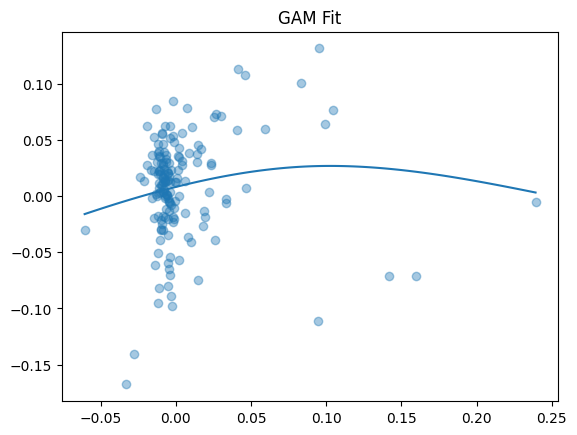

In [ ]:
from pygam import LinearGAM, s

X = df_reg[["VRP"]].values
y = df_reg["excess_ret_lead"].values

# remove rows with NaN/Inf in X or y
mask = np.isfinite(X).all(axis=1) & np.isfinite(y)
X_clean = X[mask]
y_clean = y[mask]

gam = LinearGAM(s(0, n_splines=5)).fit(X_clean, y_clean)

# Plot
XX = np.linspace(X_clean.min(), X_clean.max(), 100).reshape(-1, 1)
pred = gam.predict(XX)

plt.scatter(X_clean, y_clean, alpha=0.4)
plt.plot(XX, pred)
plt.title("GAM Fit")
plt.show()

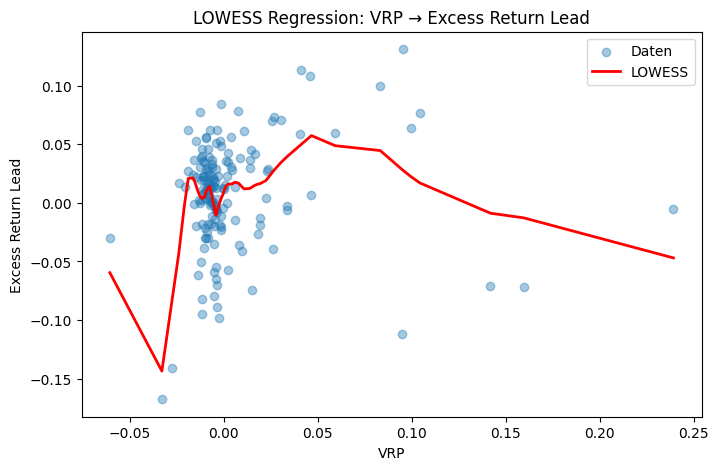

In [23]:
# LOWESS-Regression: excess_ret_lead auf VRP
loess_data = df_reg[["VRP", "IV", "CAY", "excess_ret_lead"]].dropna().sort_values("VRP")

loess_fit = sm.nonparametric.lowess(
    endog=loess_data["excess_ret_lead"],
    exog=loess_data["VRP"],
    frac=0.3,   # Glättungsgrad
    it=0,
    return_sorted=True
)

plt.figure(figsize=(8, 5))
plt.scatter(loess_data["VRP"], loess_data["excess_ret_lead"], alpha=0.4, label="Daten")
plt.plot(loess_fit[:, 0], loess_fit[:, 1], color="red", linewidth=2, label="LOWESS")
plt.xlabel("VRP")
plt.ylabel("Excess Return Lead")
plt.title("LOWESS Regression: VRP → Excess Return Lead")
plt.legend()
plt.show()